In [21]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch
import matplotlib.pyplot as plt

### Data Prep

In [2]:
data = pd.read_csv(r"C:\Users\mahes\Desktop\GitProjects\hcdata_classifier\healthcare_dataset.csv")
data.head()
data.dtypes

Name                      str
Age                     int64
Gender                    str
Blood Type                str
Medical Condition         str
Date of Admission         str
Doctor                    str
Hospital                  str
Insurance Provider        str
Billing Amount        float64
Room Number             int64
Admission Type            str
Discharge Date            str
Medication                str
Test Results              str
dtype: object

#### Choose feature columns and drop duplicates

In [3]:
data_cols = data[['Age', 'Gender', 'Blood Type', 'Medical Condition', 'Admission Type', 'Medication', 'Test Results']]
data_cols = data_cols.drop_duplicates()
data_cols

,Age,Gender,Blood Type,Medical Condition,Admission Type,Medication,Test Results
0,30,Male,B-,Cancer,Urgent,Paracetamol,Normal
1,62,Male,A+,Obesity,Emergency,Ibuprofen,Inconclusive
2,76,Female,A-,Obesity,Emergency,Aspirin,Normal
3,28,Female,O+,Diabetes,Elective,Ibuprofen,Abnormal
4,43,Female,AB+,Cancer,Urgent,Penicillin,Abnormal
...,...,...,...,...,...,...,...
55494,67,Male,O+,Arthritis,Emergency,Ibuprofen,Normal
55495,42,Female,O+,Asthma,Elective,Penicillin,Abnormal
55496,61,Female,AB-,Obesity,Elective,Aspirin,Normal
55497,38,Female,B+,Hypertension,Urgent,Ibuprofen,Abnormal


<Axes: title={'center': 'Test Results Distribution'}, xlabel='Test Results'>

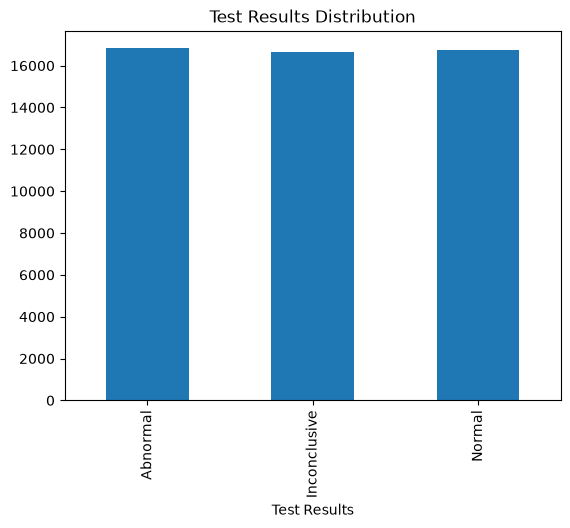

In [4]:
data_cols.groupby('Test Results').size().plot(kind='bar', title='Test Results Distribution')

#### Encode categorical columns

In [5]:
categorical_cols = ['Gender', 'Blood Type', 'Medical Condition', 'Admission Type', 'Medication']
for col in categorical_cols:
    print(f"\n{col}:")
    print(data_cols[col].value_counts().sort_index())
    print(f"Number of categories: {data_cols[col].nunique()}")


Gender:
Gender
Female    25073
Male      25139
Name: count, dtype: int64
Number of categories: 2

Blood Type:
Blood Type
A+     6299
A-     6277
AB+    6309
AB-    6288
B+     6267
B-     6271
O+     6265
O-     6236
Name: count, dtype: int64
Number of categories: 8

Medical Condition:
Medical Condition
Arthritis       8449
Asthma          8284
Cancer          8343
Diabetes        8421
Hypertension    8372
Obesity         8343
Name: count, dtype: int64
Number of categories: 6

Admission Type:
Admission Type
Elective     16919
Emergency    16473
Urgent       16820
Name: count, dtype: int64
Number of categories: 3

Medication:
Medication
Aspirin        10027
Ibuprofen      10072
Lipitor        10095
Paracetamol    10012
Penicillin     10006
Name: count, dtype: int64
Number of categories: 5


In [6]:
target_col = 'Test Results'
feature_cols = ['Age', 'Gender', 'Blood Type', 'Medical Condition', 'Admission Type', 'Medication']

X_raw = data_cols[feature_cols].copy()
y_raw = data_cols[target_col].copy()

X = pd.get_dummies(X_raw, columns=categorical_cols, dtype=float)

print(f"Shape of encoded features: {X.shape}")
print('Encoded feature columns:')
print(X.columns.tolist())

display(X.head())

Shape of encoded features: (50212, 25)
Encoded feature columns:
['Age', 'Gender_Female', 'Gender_Male', 'Blood Type_A+', 'Blood Type_A-', 'Blood Type_AB+', 'Blood Type_AB-', 'Blood Type_B+', 'Blood Type_B-', 'Blood Type_O+', 'Blood Type_O-', 'Medical Condition_Arthritis', 'Medical Condition_Asthma', 'Medical Condition_Cancer', 'Medical Condition_Diabetes', 'Medical Condition_Hypertension', 'Medical Condition_Obesity', 'Admission Type_Elective', 'Admission Type_Emergency', 'Admission Type_Urgent', 'Medication_Aspirin', 'Medication_Ibuprofen', 'Medication_Lipitor', 'Medication_Paracetamol', 'Medication_Penicillin']


,Age,Gender_Female,Gender_Male,Blood Type_A+,Blood Type_A-,Blood Type_AB+,Blood Type_AB-,Blood Type_B+,Blood Type_B-,Blood Type_O+,...,Medical Condition_Hypertension,Medical Condition_Obesity,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Medication_Aspirin,Medication_Ibuprofen,Medication_Lipitor,Medication_Paracetamol,Medication_Penicillin
0,30,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,62,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,76,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
3,28,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,43,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


#### Split data into train, test, eval: 70:20:10

In [8]:
from sklearn.model_selection import train_test_split

Xtrain_val, Xtest, Ytrain_val, Ytest = train_test_split(X, y_raw, test_size=0.1, random_state=42, stratify=y_raw)
Xtrain, Xval, Ytrain, Yval = train_test_split(Xtrain_val, Ytrain_val, test_size=0.2, random_state=42, stratify=Ytrain_val)
print(Xtrain.shape, Xval.shape, Xtest.shape)
print(Ytrain.shape, Yval.shape, Ytest.shape)

(36152, 25) (9038, 25) (5022, 25)
(36152,) (9038,) (5022,)


#### Scale Age column on trainset

In [9]:
from sklearn.preprocessing import StandardScaler

# Fit and tranform train set
age_scaler = StandardScaler()
Xtrain['Age_scaled'] = age_scaler.fit_transform(Xtrain[['Age']])
Xtrain = Xtrain.drop(columns=['Age'])

#Transform val and test sets
Xval['Age_scaled'] = age_scaler.transform(Xval[['Age']])
Xval = Xval.drop(columns=['Age'])

Xtest['Age_scaled'] = age_scaler.transform(Xtest[['Age']])
Xtest = Xtest.drop(columns=['Age'])

Xtrain

,Gender_Female,Gender_Male,Blood Type_A+,Blood Type_A-,Blood Type_AB+,Blood Type_AB-,Blood Type_B+,Blood Type_B-,Blood Type_O+,Blood Type_O-,...,Medical Condition_Obesity,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Medication_Aspirin,Medication_Ibuprofen,Medication_Lipitor,Medication_Paracetamol,Medication_Penicillin,Age_scaled
11016,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,-1.609235
37081,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.276241
551,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.174323
732,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.284306
15565,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.887746
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25646,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.276241
48622,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.284306
21424,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.683911
7084,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.123364


#### Label encode the target values

In [12]:
classes = sorted(y_raw.unique())
label_encoding = {label: i for i, label in enumerate(classes)}

Ytrain = Ytrain.map(label_encoding)
Yval = Yval.map(label_encoding)
Ytest = Ytest.map(label_encoding)

display(Ytrain.head())
display(Yval.head())
display(Ytest.head())

11016    1
37081    2
551      2
732      1
15565    1
Name: Test Results, dtype: int64

49988    1
26660    1
49812    0
17419    0
21008    0
Name: Test Results, dtype: int64

43354    2
22994    1
29183    1
39932    1
26669    0
Name: Test Results, dtype: int64

#### Convert to Tensors

In [ ]:
Xtrain_tensor = torch.tensor(Xtrain.to_numpy(dtype='float32'), dtype=torch.float32)
Ytrain_tensor = torch.tensor(Ytrain.to_numpy(dtype='int64'), dtype=torch.long)


Xval_tensor = torch.tensor(Xval.to_numpy(dtype='float32'), dtype=torch.float32)
Yval_tensor = torch.tensor(Yval.to_numpy(dtype='int64'), dtype=torch.long)

Xtest_tensor = torch.tensor(Xtest.to_numpy(dtype='float32'), dtype=torch.float32)
Ytest_tensor = torch.tensor(Ytest.to_numpy(dtype='int64'), dtype=torch.long)



print(f"train tensor shape: {Xtrain_tensor.shape}, val tensor shape: {Xval_tensor.shape}, test tensor shape: {Xtest_tensor.shape}")
print(f"train labels shape: {Ytrain_tensor.shape}, val labels shape: {Yval_tensor.shape}, test labels shape: {Ytest_tensor.shape}")


train tensor shape: torch.Size([36152, 25]), val tensor shape: torch.Size([9038, 25]), test tensor shape: torch.Size([5022, 25])
train labels shape: torch.Size([36152]), val labels shape: torch.Size([9038]), test labels shape: torch.Size([5022])


#### Define DataLoader

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

train_dataset = TensorDataset(Xtrain_tensor, Ytrain_tensor)
val_dataset = TensorDataset(Xval_tensor, Yval_tensor)
test_dataset = TensorDataset(Xtest_tensor, Ytest_tensor)

train_shuffled_dataset = TensorDataset(Xtrain_tensor, Ytrain_tensor_shuffled)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

train_shuffled_loader = DataLoader(train_shuffled_dataset, batch_size=64, shuffle=True)

print(f"train loader length: {len(train_loader)}, val loader length: {len(val_loader)}, test loader length: {len(test_loader)}")

train loader length: 565, val loader length: 142, test loader length: 79


In [18]:
import torch.nn as nn

class healthcare_classifier(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(healthcare_classifier, self).__init__()
        self.layer1 = nn.Linear(input_size, hidden_size)
        self.activation1 = nn.ReLU()
        self.layer2 = nn.Linear(hidden_size, output_size)
        
    def forward(self, x):
        x = self.layer1(x)
        x = self.activation1(x)
        x = self.layer2(x)
        return x


#### Forward Pass on one batch

In [20]:
model_1batch = healthcare_classifier(Xtrain_tensor.shape[1], 8, len(classes))
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1batch.parameters(), lr=0.001)


model_1batch.train()
optimizer.zero_grad()
outputs = model_1batch(next(iter(train_loader))[0])
loss = criterion(outputs, next(iter(train_loader))[1])

print(len(outputs))
print(loss.item())

64
1.1389371156692505


#### Overfit on 1 batch

Epoch 1/250, Train Loss: 1.1025, Val Loss: 1.1085
Epoch 2/250, Train Loss: 1.0934, Val Loss: 1.1074
Epoch 3/250, Train Loss: 1.0848, Val Loss: 1.1066
Epoch 4/250, Train Loss: 1.0766, Val Loss: 1.1061
Epoch 5/250, Train Loss: 1.0688, Val Loss: 1.1059
Epoch 6/250, Train Loss: 1.0613, Val Loss: 1.1059
Epoch 7/250, Train Loss: 1.0542, Val Loss: 1.1061
Epoch 8/250, Train Loss: 1.0473, Val Loss: 1.1066
Epoch 9/250, Train Loss: 1.0408, Val Loss: 1.1072
Epoch 10/250, Train Loss: 1.0345, Val Loss: 1.1079
Epoch 11/250, Train Loss: 1.0284, Val Loss: 1.1088
Epoch 12/250, Train Loss: 1.0225, Val Loss: 1.1097
Epoch 13/250, Train Loss: 1.0167, Val Loss: 1.1107
Epoch 14/250, Train Loss: 1.0111, Val Loss: 1.1118
Epoch 15/250, Train Loss: 1.0056, Val Loss: 1.1128
Epoch 16/250, Train Loss: 1.0001, Val Loss: 1.1138
Epoch 17/250, Train Loss: 0.9947, Val Loss: 1.1149
Epoch 18/250, Train Loss: 0.9894, Val Loss: 1.1158
Epoch 19/250, Train Loss: 0.9840, Val Loss: 1.1168
Epoch 20/250, Train Loss: 0.9787, Val Lo

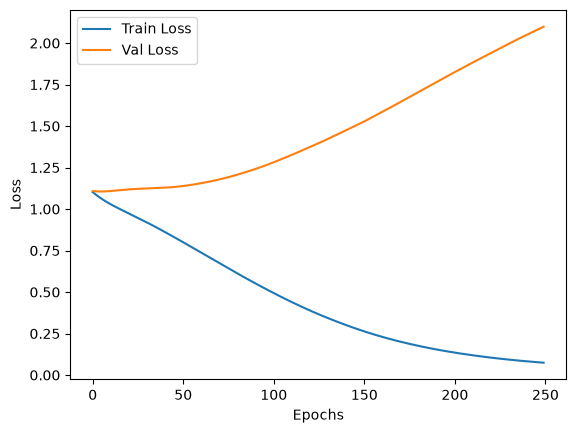

In [34]:
model_overfit = healthcare_classifier(Xtrain_tensor.shape[1], 128, len(classes))
loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_overfit.parameters(), lr=0.001)

train_losses = []
val_losses = []

epochs=250

trainbatch = next(iter(train_loader))
valbatch = next(iter(val_loader))

for epoch in range(epochs):
    model_overfit.train()
    optimizer.zero_grad()
    output = model_overfit(trainbatch[0])
    train_loss = loss(output, trainbatch[1])
    train_loss.backward()
    optimizer.step()
    train_losses.append(train_loss.item())

    model_overfit.eval()
    with torch.no_grad():
        val_output = model_overfit(valbatch[0])
        val_loss = loss(val_output, valbatch[1])
        val_losses.append(val_loss.item())


    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {train_losses[-1]:.4f}, Val Loss: {val_losses[-1]:.4f}")

plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

#### Full Train Loop

In [ ]:
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs):

    best_loss = float('inf')
    avgtrainlosses = []
    avgvallosses = []

    for epoch in range(epochs):
        train_losses = []
        val_losses = []
        model.train()
        for Xbatch, Ybatch in train_loader:
            optimizer.zero_grad()

            outputs = model(Xbatch)
            loss = criterion(outputs, Ybatch)

            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        avg_train_loss = sum(train_losses) / len(train_loader)
        avgtrainlosses.append(avg_train_loss)

        model.eval()
        with torch.no_grad():
            for Xbatch, Ybatch in val_loader:
                outputs = model(Xbatch)
                loss = criterion(outputs, Ybatch)
                val_losses.append(loss.item())
            avg_val_loss = sum(val_losses) / len(val_loader)
            avgvallosses.append(avg_val_loss)
            if avg_val_loss < best_loss:
                best_loss = avg_val_loss
                torch.save(model.state_dict(), 'best_model.pth')
                print('Best model saved.')
        print(f'Epoch [{epoch+1}/{epochs}], Avg Train Loss: {avg_train_loss:.4f}, Avg Val Loss: {avg_val_loss:.4f}')


    plt.plot(avgtrainlosses, label='Avg Train Loss')
    plt.plot(avgvallosses, label='Avg Val Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

                


Best model saved.
Epoch [1/20], Avg Train Loss: 1.1005, Avg Val Loss: 1.0998
Epoch [2/20], Avg Train Loss: 1.0987, Avg Val Loss: 1.0998
Epoch [3/20], Avg Train Loss: 1.0982, Avg Val Loss: 1.1002
Epoch [4/20], Avg Train Loss: 1.0978, Avg Val Loss: 1.1007
Epoch [5/20], Avg Train Loss: 1.0974, Avg Val Loss: 1.1014
Epoch [6/20], Avg Train Loss: 1.0968, Avg Val Loss: 1.1019
Epoch [7/20], Avg Train Loss: 1.0965, Avg Val Loss: 1.1016
Epoch [8/20], Avg Train Loss: 1.0959, Avg Val Loss: 1.1018
Epoch [9/20], Avg Train Loss: 1.0953, Avg Val Loss: 1.1017
Epoch [10/20], Avg Train Loss: 1.0949, Avg Val Loss: 1.1028
Epoch [11/20], Avg Train Loss: 1.0944, Avg Val Loss: 1.1029
Epoch [12/20], Avg Train Loss: 1.0941, Avg Val Loss: 1.1038
Epoch [13/20], Avg Train Loss: 1.0935, Avg Val Loss: 1.1044
Epoch [14/20], Avg Train Loss: 1.0933, Avg Val Loss: 1.1037
Epoch [15/20], Avg Train Loss: 1.0930, Avg Val Loss: 1.1042
Epoch [16/20], Avg Train Loss: 1.0926, Avg Val Loss: 1.1051
Epoch [17/20], Avg Train Loss: 

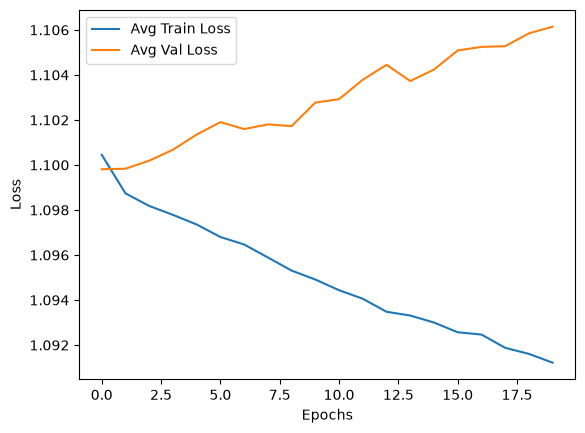

In [57]:
input_size = Xtrain_tensor.shape[1]
hidden_size = 64
output_size = len(classes)

model = healthcare_classifier(input_size, hidden_size, output_size)


criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
epochs = 20

train_model(model, train_loader, val_loader, criterion, optimizer, epochs)

In [ ]:
torch.manual_seed(42)  # for reproducibility
Ytrain_tensor_shuffled = Ytrain_tensor[torch.randperm(Ytrain_tensor.size(0))]
train_dataset_shuffled = TensorDataset(Xtrain_tensor, Ytrain_tensor_shuffled)
train_shuffled_loader = DataLoader(train_dataset_shuffled, batch_size=64, shuffle=True)


print(Ytrain_tensor_shuffled.unique(return_counts=True))
print(Ytrain_tensor.unique(return_counts=True))

print((Ytrain_tensor == Ytrain_tensor_shuffled).all())

(tensor([0, 1, 2]), tensor([12113, 11996, 12043]))
(tensor([0, 1, 2]), tensor([12113, 11996, 12043]))
tensor(False)


Best model saved.
Epoch [1/20], Avg Train Loss: 1.1038, Avg Val Loss: 1.1026
Best model saved.
Epoch [2/20], Avg Train Loss: 1.0992, Avg Val Loss: 1.1019
Best model saved.
Epoch [3/20], Avg Train Loss: 1.0972, Avg Val Loss: 1.1010
Epoch [4/20], Avg Train Loss: 1.0958, Avg Val Loss: 1.1015
Epoch [5/20], Avg Train Loss: 1.0949, Avg Val Loss: 1.1013
Epoch [6/20], Avg Train Loss: 1.0942, Avg Val Loss: 1.1020
Epoch [7/20], Avg Train Loss: 1.0934, Avg Val Loss: 1.1019
Epoch [8/20], Avg Train Loss: 1.0926, Avg Val Loss: 1.1031
Epoch [9/20], Avg Train Loss: 1.0920, Avg Val Loss: 1.1033
Epoch [10/20], Avg Train Loss: 1.0917, Avg Val Loss: 1.1032
Epoch [11/20], Avg Train Loss: 1.0912, Avg Val Loss: 1.1042
Epoch [12/20], Avg Train Loss: 1.0906, Avg Val Loss: 1.1047
Epoch [13/20], Avg Train Loss: 1.0900, Avg Val Loss: 1.1047
Epoch [14/20], Avg Train Loss: 1.0896, Avg Val Loss: 1.1051
Epoch [15/20], Avg Train Loss: 1.0892, Avg Val Loss: 1.1060
Epoch [16/20], Avg Train Loss: 1.0885, Avg Val Loss: 1.

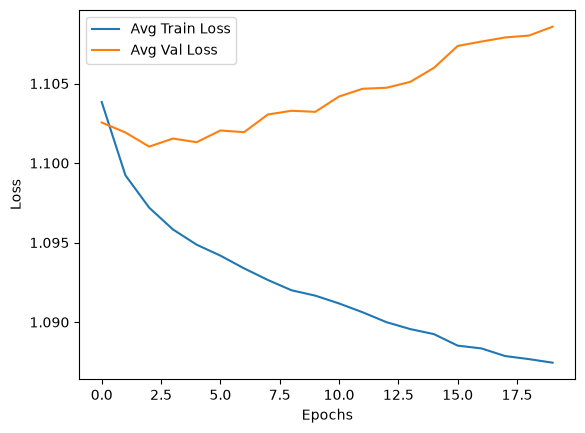

In [ ]:

train_model(model, train_shuffled_loader, val_loader, criterion, optimizer, epochs)


#### Logistic Regression

In [49]:
from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression()
log_reg.fit(Xtrain_tensor.numpy(), Ytrain_tensor.numpy())
print(f"Training accuracy: {log_reg.score(Xtrain_tensor.numpy(), Ytrain_tensor.numpy())}")
print(f"Validation accuracy: {log_reg.score(Xval_tensor.numpy(), Yval_tensor.numpy())}")
print(f"Test accuracy: {log_reg.score(Xtest_tensor.numpy(), Ytest_tensor.numpy())}")

Training accuracy: 0.3465645054215534
Validation accuracy: 0.32529320646160653
Test accuracy: 0.32238152130625247


#### Per feature class proportions

In [51]:
proportions_age = pd.crosstab(data_cols['Age'], data_cols['Test Results'], normalize='columns')
print(proportions_age)

Test Results  Abnormal  Inconclusive    Normal
Age                                           
13            0.000476      0.000180  0.000179
14            0.000297      0.000300  0.000478
15            0.000654      0.000420  0.000598
16            0.000594      0.000420  0.000418
17            0.000773      0.000600  0.000478
..                 ...           ...       ...
85            0.013790      0.013805  0.013093
86            0.000476      0.000960  0.001016
87            0.000773      0.000780  0.000299
88            0.000357      0.000660  0.000478
89            0.000238      0.000120  0.000120

[77 rows x 3 columns]


In [52]:
proportions_gender = pd.crosstab(data_cols['Gender'], data_cols['Test Results'], normalize='columns')
print(proportions_gender)

Test Results  Abnormal  Inconclusive    Normal
Gender                                        
Female        0.502199      0.502191  0.493633
Male          0.497801      0.497809  0.506367


In [53]:
proportions_bloodtype = pd.crosstab(data_cols['Blood Type'], data_cols['Test Results'], normalize='columns')
print(proportions_bloodtype)

Test Results  Abnormal  Inconclusive    Normal
Blood Type                                    
A+            0.124108      0.127063  0.125187
A-            0.125713      0.123762  0.125546
AB+           0.124703      0.127183  0.125067
AB-           0.126070      0.122082  0.127518
B+            0.123157      0.128204  0.123094
B-            0.126605      0.124242  0.123812
O+            0.125951      0.123642  0.124709
O-            0.123692      0.123822  0.125067


In [54]:
proportions_medicalcondition = pd.crosstab(data_cols['Medical Condition'], data_cols['Test Results'], normalize='columns')
print(proportions_medicalcondition)

Test Results       Abnormal  Inconclusive    Normal
Medical Condition                                  
Arthritis          0.171243      0.169017  0.164524
Asthma             0.162447      0.163195  0.169307
Cancer             0.166786      0.165536  0.166139
Diabetes           0.169223      0.166557  0.167334
Hypertension       0.162506      0.169258  0.168470
Obesity            0.167796      0.166437  0.164226


In [55]:
proportions_admissiontype = pd.crosstab(data_cols['Admission Type'], data_cols['Test Results'], normalize='columns')
print(proportions_admissiontype)

Test Results    Abnormal  Inconclusive    Normal
Admission Type                                  
Elective        0.338326      0.333053  0.339451
Emergency       0.327033      0.329152  0.328033
Urgent          0.334641      0.337795  0.332516


In [56]:
proportions_medication = pd.crosstab(data_cols['Medication'], data_cols['Test Results'], normalize='columns')
print(proportions_medication)

Test Results  Abnormal  Inconclusive    Normal
Medication                                    
Aspirin       0.201141      0.197347  0.200574
Ibuprofen     0.201676      0.198908  0.201172
Lipitor       0.199001      0.204249  0.199916
Paracetamol   0.200666      0.199988  0.197525
Penicillin    0.197515      0.199508  0.200813


#### Test Set Evaluation

In [60]:
from torchmetrics.classification import MulticlassAccuracy, MulticlassConfusionMatrix

trained_model = healthcare_classifier(25, 64, 3)  # Assuming the model class is named healthcare_classifier_model
trained_ckp = torch.load('C:\\Users\\mahes\\Documents\\GitHub\\practice\\healthcare_classifier\\best_model.pth', weights_only=True)
trained_model.load_state_dict(trained_ckp)

acc_metric = MulticlassAccuracy(num_classes=3)
cm_metric = MulticlassConfusionMatrix(num_classes=3)


test_losses = []
trained_model.eval()
with torch.no_grad():
    for Xbatch, Ybatch in test_loader:
        outputs = trained_model(Xbatch)
        loss = criterion(outputs, Ybatch)  # Assuming you have defined the criterion (loss function)
        test_losses.append(loss.item())

        preds = torch.argmax(outputs, dim=1)
        
        acc_metric.update(preds, Ybatch)
        cm_metric.update(preds, Ybatch)


# 2. Compute final metrics after the loop finishes
final_accuracy = acc_metric.compute().item()
final_confusion_matrix = cm_metric.compute()  # Returns a PyTorch tensor

print(f"Validation Accuracy: {final_accuracy:.4f}")
print("Confusion Matrix:\n", final_confusion_matrix)

# 3. CRUCIAL: Reset metric states for the next epoch/evaluation run
acc_metric.reset()
cm_metric.reset()


Validation Accuracy: 0.3230
Confusion Matrix:
 tensor([[638, 210, 835],
        [634, 198, 834],
        [658, 227, 788]])


##### TODO:

Run the test evaluation and send me:

1. The wobble you computed and the 95% range for your test accuracy.
2. The test accuracy, and whether it's inside that range.
3. The confusion matrix, plus the predicted-class counts (a count of each predicted class). Which of the two patterns above does it look like?
4. The result of the excluded-column check.
After that we'll choose the next dataset and go through Step 6, which covers diagnosing underfitting and overfitting on data that actually has signal.


In [61]:
import numpy as np

print(np.sqrt((0.323 *(1-0.323))/5022))

0.00659868263405493


In [62]:
len(preds)

30